# Day 2: Machine Learning Model Comparison

## Objective
Train and compare Decision Tree, Random Forest, and SVM models
against the Day 1 Logistic Regression baseline.

We will use the same dataset, preprocessing strategy, and
train-test split to ensure a fair comparison.

In [62]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score, classification_report,
    confusion_matrix
)

In [63]:
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

CLEANED_DATA_PATH = (
    BASE_DIR / "data" / "processed" / "cleaned_data.csv"
)

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [64]:
df = pd.read_csv(CLEANED_DATA_PATH)

In [65]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [66]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [67]:
import sys

sys.path.insert(0, str(BASE_DIR / "src"))

from retailmind.pipeline import build_pipeline

print("Pipeline imported successfully!")

Pipeline imported successfully!


In [68]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [69]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

In [70]:
models = {}

for name, classifier in classifiers.items():
    models[name] = build_pipeline(
        X_train,
        classifier=classifier
    )

print("Pipelines created successfully!")

for name, model in models.items():
    print(name, ":", type(model).__name__)

Pipelines created successfully!
Decision Tree : Pipeline
Random Forest : Pipeline
SVM : Pipeline


## Model Training

Train Decision Tree, Random Forest and SVM using the same training dataset.

In [71]:
for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    print(f"{name} training completed!\n")

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training SVM...


c:\Users\SUBHOJIT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!



In [72]:
for name, model in models.items():
    print(f"{name}:")
    print("Fitted:", hasattr(model, "classes_"))
    print("Classes:", model.classes_)
    print("-" * 40)

Decision Tree:
Fitted: True
Classes: [0 1]
----------------------------------------
Random Forest:
Fitted: True
Classes: [0 1]
----------------------------------------
SVM:
Fitted: True
Classes: [0 1]
----------------------------------------


In [73]:
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"

    model_path = MODEL_DIR / filename

    joblib.dump(model, model_path)

    print(f"Saved {name} at {model_path}")

Saved Decision Tree at d:\RetailMind\models\decision_tree.joblib
Saved Random Forest at d:\RetailMind\models\random_forest.joblib
Saved SVM at d:\RetailMind\models\svm.joblib


## Model Evaluation and Comparison

Evaluate the Day 1 Logistic Regression baseline against the three
newly trained models using the same test dataset.


In [74]:
baseline_model = joblib.load(
    BASE_DIR / "models" / "churn_pipeline.joblib"
)

print("Day 1 Logistic Regression model loaded!")

Day 1 Logistic Regression model loaded!


In [75]:
all_models = {
    "Logistic Regression": baseline_model,
    "Decision Tree": models["Decision Tree"],
    "Random Forest": models["Random Forest"],
    "SVM": models["SVM"]
}

print("Total models:", len(all_models))

Total models: 4


In [76]:
predictions = {}
probabilities = {}

for name, model in all_models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name}: predictions generated")

Logistic Regression: predictions generated
Decision Tree: predictions generated
Random Forest: predictions generated
SVM: predictions generated


In [77]:
results = []

for name in all_models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    results.append(metrics)

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841298
1,Decision Tree,0.731725,0.494565,0.486631,0.490566,0.653696
2,Random Forest,0.765791,0.552133,0.622995,0.585427,0.821759
3,SVM,0.743790,0.511504,0.772727,0.615548,0.821065


In [78]:
comparison_df = comparison_df.sort_values(
    by=["Recall", "F1 Score"],
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841298
1,SVM,0.743790,0.511504,0.772727,0.615548,0.821065
2,Random Forest,0.765791,0.552133,0.622995,0.585427,0.821759
3,Decision Tree,0.731725,0.494565,0.486631,0.490566,0.653696


In [79]:
for name in all_models:

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.82      0.82      1035
       Churn       0.49      0.49      0.49       374

    accuracy                           0.73      1409
   macro avg       0.66      0.65      0.65      1409
weighted avg       0.73      0.73      0.73      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78   

Matplotlib is building the font cache; this may take a moment.


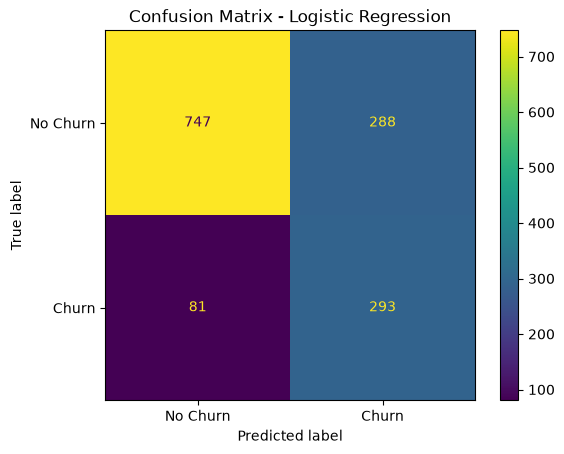

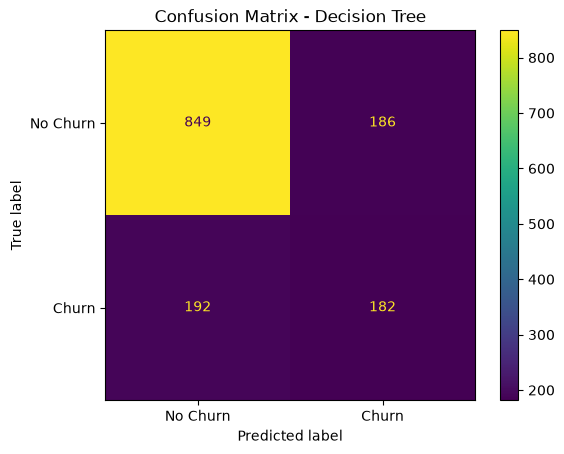

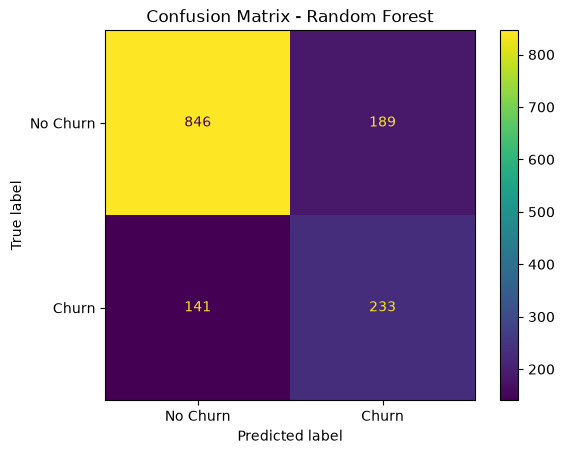

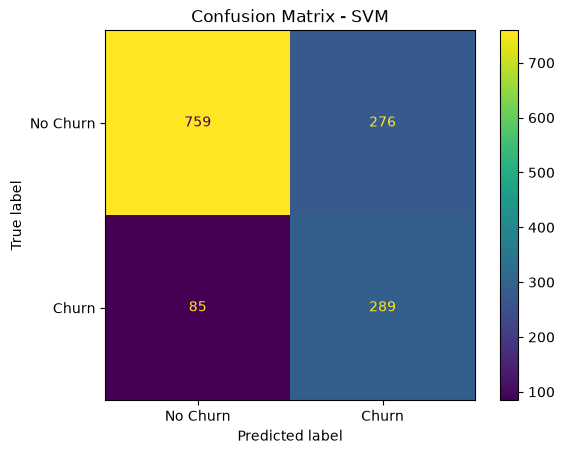

In [82]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name in all_models:

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [81]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 921.6 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.5 MB 1.2 MB/s eta 0:00:07
   ---- ----------------------------------- 1.0/9.5 MB 1.2 MB/s eta 0:00:07
   ------ --------------------------------- 1.6/9.5 MB 1.3 MB/s eta 0:00:07
   ------- -------------------------------- 1.8/9.5 MB 1.3 MB/s eta 0:00:06
   -------- ------------------------------- 2.1/9.5 MB 1.4 MB/s eta 0:00:06
   --------- ------------------------------ 2.4/9.5 MB 1.3 MB/s eta 0:00:06
   --------- ------------------------------ 2.4/9.5 MB 1.3 MB/s eta 0:00:06
   --------- ------------------------------ 2.4/9.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [83]:
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_json(
    REPORT_DIR / "model_comparison.json",
    orient="records",
    indent=4
)

print("Model comparison report saved!")

Model comparison report saved!
